<a href="https://colab.research.google.com/github/velezverespeter/energy-trading-risk/blob/main/notebooks/04_credit_risk.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

daily = pd.read_csv("si_prices_daily.csv", index_col=0, parse_dates=True)
daily = daily[daily.index < "2026-01-01"]
daily["forward"] = daily["base"].rolling(30).mean()
daily.tail(3)

,base,peak,forward
date,,,
2025-12-29,101.451667,109.104167,112.983458
2025-12-30,90.520000,95.630000,112.573806
2025-12-31,95.426250,102.776667,111.103431


In [2]:
pogodba = daily.loc["2021-07-01":"2022-12-31"].copy()

pogodbena_cena = pogodba["forward"].iloc[0]
print(f"Pogodbena cena: {pogodbena_cena:.2f} EUR/MWh")

Pogodbena cena: 79.34 EUR/MWh


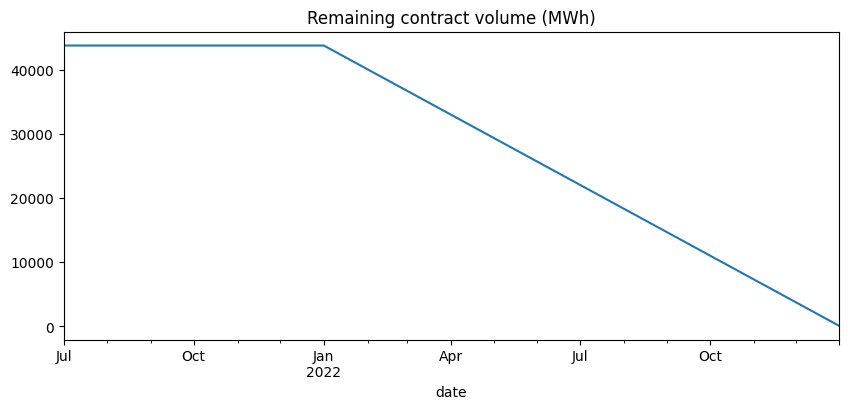

In [3]:
zacetek_dobave = pd.Timestamp("2022-01-01")
konec_dobave = pd.Timestamp("2023-01-01")

def preostala_kolicina(datum):
    if datum < zacetek_dobave:
        return 5 * 24 * 365
    else:
        return 5 * 24 * (konec_dobave - datum).days

pogodba["remaining"] = [preostala_kolicina(d) for d in pogodba.index]

pogodba["remaining"].plot(figsize=(10, 4), title="Remaining contract volume (MWh)")
plt.show()

In [4]:
pogodba["exposure"] = (pogodba["forward"] - pogodbena_cena).clip(lower=0) * pogodba["remaining"]

print(f"Največja izpostavljenost: {pogodba['exposure'].max():,.0f} EUR, dne {pogodba['exposure'].idxmax().date()}")
print(f"Povprečna izpostavljenost: {pogodba['exposure'].mean():,.0f} EUR")

Največja izpostavljenost: 8,509,806 EUR, dne 2021-12-23
Povprečna izpostavljenost: 3,707,311 EUR


In [5]:
rast_95 = daily["forward"].diff(30).quantile(0.95)
print(f"95 % najslabša 30-dnevna rast cene: {rast_95:.2f} EUR/MWh")

pogodba["pfe"] = (pogodba["forward"] + rast_95 - pogodbena_cena).clip(lower=0) * pogodba["remaining"]

print(f"Največji PFE: {pogodba['pfe'].max():,.0f} EUR")

95 % najslabša 30-dnevna rast cene: 89.96 EUR/MWh
Največji PFE: 12,450,236 EUR


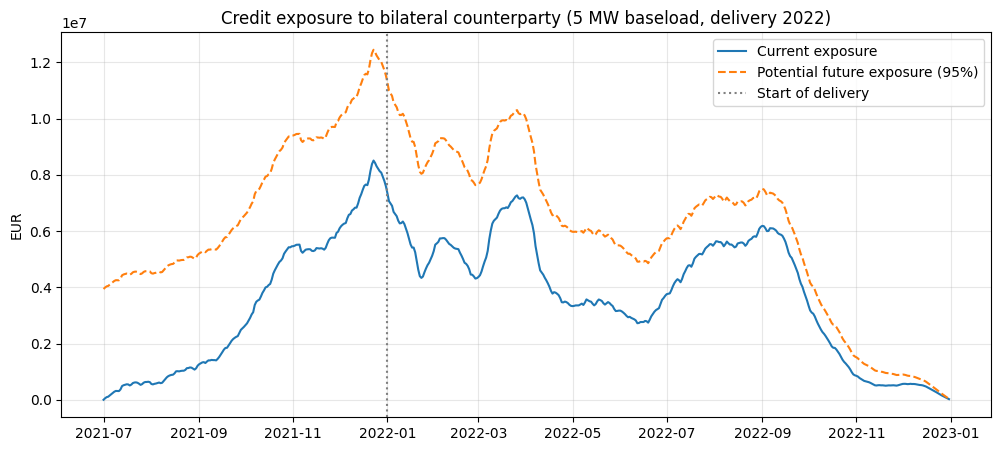

In [6]:
plt.figure(figsize=(12, 5))
plt.plot(pogodba.index, pogodba["exposure"], label="Current exposure")
plt.plot(pogodba.index, pogodba["pfe"], linestyle="--", label="Potential future exposure (95%)")
plt.axvline(zacetek_dobave, color="grey", linestyle=":", label="Start of delivery")
plt.title("Credit exposure to bilateral counterparty (5 MW baseload, delivery 2022)")
plt.ylabel("EUR")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("credit_exposure.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
pd_po_bonitetah = {
    "AA": 0.0002,
    "A": 0.0005,
    "BBB": 0.0015,
    "BB": 0.006,
    "B": 0.03,
}

lgd = 0.60
ead = pogodba["exposure"].mean()

for boniteta, verjetnost in pd_po_bonitetah.items():
    el = verjetnost * lgd * ead
    print(f"{boniteta:>4}:  PD = {verjetnost:.2%}   pričakovana izguba = {el:,.0f} EUR")

  AA:  PD = 0.02%   pričakovana izguba = 445 EUR
   A:  PD = 0.05%   pričakovana izguba = 1,112 EUR
 BBB:  PD = 0.15%   pričakovana izguba = 3,337 EUR
  BB:  PD = 0.60%   pričakovana izguba = 13,346 EUR
   B:  PD = 3.00%   pričakovana izguba = 66,732 EUR
